
🔎 Profil 1: phi=0.11900000274181366, T=20.0, wc=0.44999998807907104, S0=0.6000000238418579, t_h=2.0
✅ Paramètres estimés:
   Dv = 1.03e-08 m²/s
   α = 0.0853
   n = 1.86
📉 Loss MSE pour ce profil : nan

🔎 Profil 2: phi=0.11900000274181366, T=20.0, wc=0.44999998807907104, S0=0.6000000238418579, t_h=24.0
✅ Paramètres estimés:
   Dv = 1.07e-08 m²/s
   α = 0.0922
   n = 1.80
📉 Loss MSE pour ce profil : nan

🔎 Profil 3: phi=0.11900000274181366, T=20.0, wc=0.44999998807907104, S0=0.6000000238418579, t_h=72.0
✅ Paramètres estimés:
   Dv = 1.06e-08 m²/s
   α = 0.0982
   n = 1.69
📉 Loss MSE pour ce profil : nan
🧪 Test manuel - Paramètres estimés:
   Dv = 1.06e-08 m²/s
   α = 0.0982
   n = 1.69


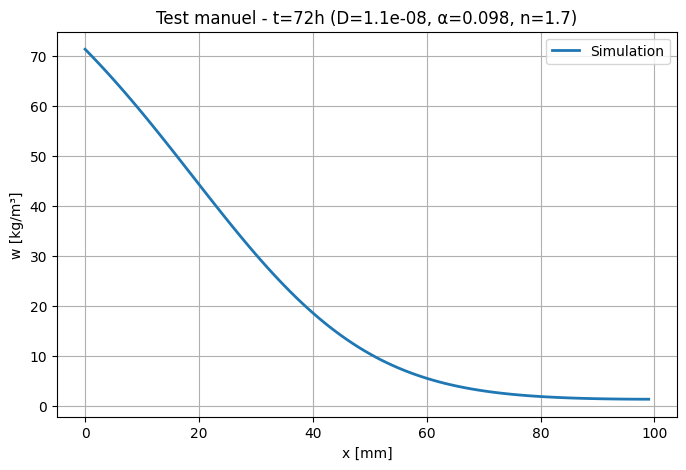

🚀 Démarrage de l'entraînement avec stabilisation...

🔎 Profil 1/3: phi=0.119, T=20.0, wc=0.450, S0=0.600, t_h=2.0
📊 Paramètres: D=1.03e-08, α=0.0853, n=1.86
📊 Nombre de points trouvés : 6
✅ Profil accepté. Loss = 0.952107

🔎 Profil 2/3: phi=0.119, T=20.0, wc=0.450, S0=0.600, t_h=24.0
📊 Paramètres: D=1.07e-08, α=0.0922, n=1.80
📊 Nombre de points trouvés : 6
✅ Profil accepté. Loss = 0.90322024

🔎 Profil 3/3: phi=0.119, T=20.0, wc=0.450, S0=0.600, t_h=72.0
📊 Paramètres: D=1.06e-08, α=0.0982, n=1.69
📊 Nombre de points trouvés : 19
✅ Profil accepté. Loss = 0.9170243

📉 Epoch 0, Loss: 9.2412e-01
   Moyennes: D=1.05e-08, α=0.0919, n=1.78

🔎 Profil 1/3: phi=0.119, T=20.0, wc=0.450, S0=0.600, t_h=2.0
📊 Paramètres: D=1.04e-08, α=0.0854, n=1.85
📊 Nombre de points trouvés : 6
✅ Profil accepté. Loss = 0.9394042

🔎 Profil 2/3: phi=0.119, T=20.0, wc=0.450, S0=0.600, t_h=24.0
📊 Paramètres: D=1.09e-08, α=0.0924, n=1.80
📊 Nombre de points trouvés : 6
✅ Profil accepté. Loss = 0.89307356

🔎 Profil 3/3: ph

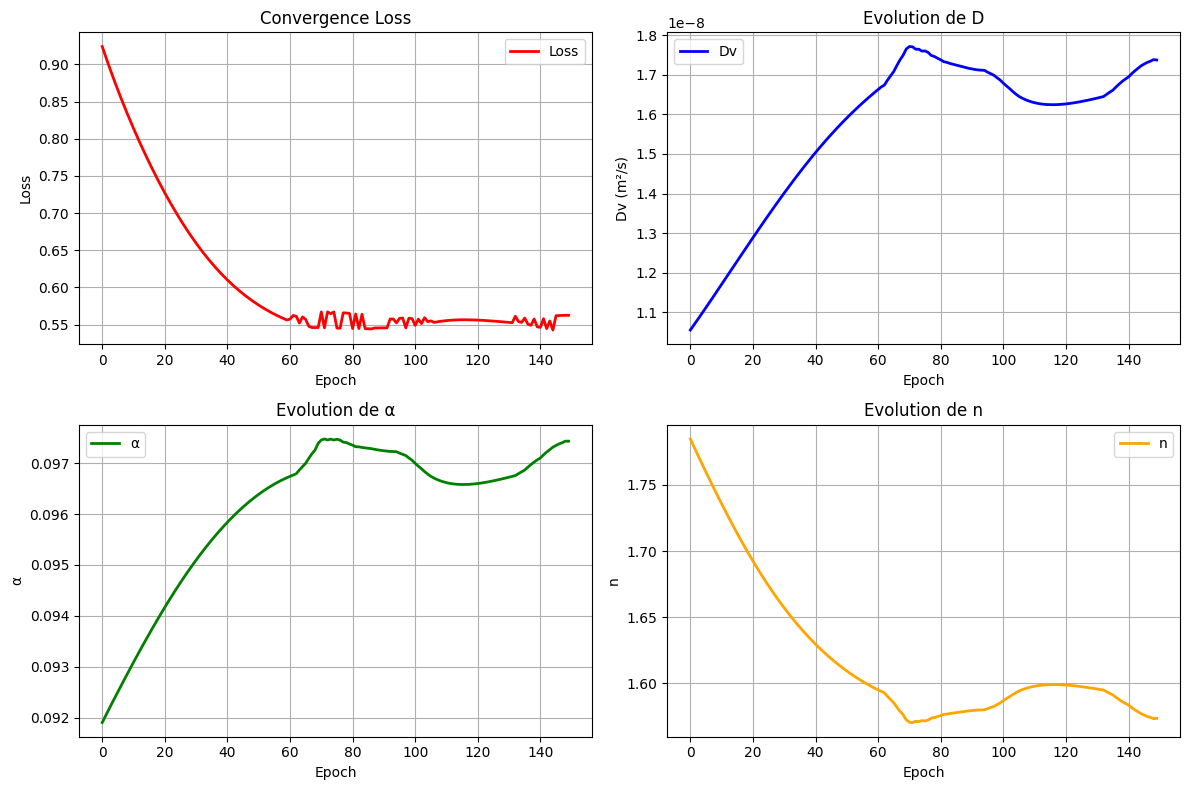

🎉 Entraînement terminé ! Le modèle estime maintenant D, α et n simultanément.


In [17]:
# 🔁 Version V5 - PINN entraîné sur plusieurs bétons avec estimation de D, α et n

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# 📥 Charger le dataset
df_all = pd.read_csv("Dataset_multi-temps_format_.csv")

# 📊 Calcul automatique des moyennes et écarts-types
input_columns = ['phi', 'T', 'w_c', 'S0', 't_h']
X_all = df_all[input_columns].drop_duplicates().values.astype(np.float32)
X_mean = tf.constant(np.mean(X_all, axis=0), dtype=tf.float32)
X_std = tf.constant(np.std(X_all, axis=0), dtype=tf.float32)
X_std_safe = tf.where(X_std == 0.0, tf.ones_like(X_std), X_std)

# === 2. Normalisation ===
def normalize(x):
    return (x - X_mean) / X_std_safe

# === 3. Modèle ANN modifié pour 3 sorties ===
def build_ann_model(input_dim=5):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(20, activation='tanh'),  # Architecture plus stable
        Dense(20, activation='tanh'),
        Dense(3, activation='linear')  # 3 sorties : D, α, n
    ])
    return model

model = build_ann_model()
optimizer = Adam(learning_rate=5e-4)  # Learning rate plus faible

@tf.function
def simulate_model_tf(Dv, alpha0, nShape, S0, phi, rho_eau, dx, dt, Tmax, Nx, mode="imbibition"):
    # Convertir tous les scalaires en tf.Tensor
    dx = tf.convert_to_tensor(dx, dtype=tf.float32)
    dt = tf.convert_to_tensor(dt, dtype=tf.float32)
    Tmax = tf.convert_to_tensor(Tmax, dtype=tf.float32)
    Nx = tf.convert_to_tensor(Nx, dtype=tf.int32)

    Nt = tf.cast(tf.math.floordiv(Tmax, dt), tf.int32)
    x_vals = tf.linspace(0.0, dx * tf.cast(Nx - 1, tf.float32), Nx)

    # 🔧 Paramètres physiques (certains maintenant variables)
    Sc = 0.8
    S_cap = 0.75
    beta = 2.5
    Pc0 = 5e6
    K_in = 1.7e-20
    eta_l = 1e-3

    # ✅ Initialisation de la saturation
    if mode == "imbibition":
        S = tf.ones((Nx,), dtype=tf.float32) * 0.01
        S = tf.tensor_scatter_nd_update(S, [[0]], [S0])
    elif mode == "drainage":
        S = tf.ones((Nx,), dtype=tf.float32) * S0
    else:
        raise ValueError("Mode must be 'imbibition' or 'drainage'")

    M = tf.ones((Nx,), dtype=tf.float32) * dx
    M = tf.tensor_scatter_nd_update(M, [[0], [Nx - 1]], [dx / 2, dx / 2])

    # 📈 Fonctions de diffusion avec paramètres variables
    def Dvapeur(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        fs = alpha0 + (1.0 - alpha0) / (1.0 + tf.pow((1.0 - S_val) / (1.0 - Sc), nShape))
        return tf.clip_by_value(fs, 1e-12, 10.0) * Dv

    def Dcapi(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        dpc = -beta * Pc0 * tf.pow(S_val, -beta - 1)
        return tf.abs(dpc) * K_in / eta_l

    def D_S(S_val):
        weight = tf.math.sigmoid(50.0 * (S_val - S_cap))
        return weight * Dcapi(S_val) + (1.0 - weight) * Dvapeur(S_val)

    # 🔁 Boucle temporelle
    for _ in tf.range(Nt):
        S_old = S
        for _ in tf.range(5):  # Picard simplifié
            D_vals = D_S(S)

            D_left = (D_vals[:-1] + D_vals[1:]) / 2.0
            fluxes = D_left * (S[1:] - S[:-1]) / dx

            dS_dt = tf.zeros_like(S)

            # 🌡️ Mise à jour des points intérieurs
            interior_flux = (fluxes[1:] - fluxes[:-1]) / dx
            dS_dt = tf.tensor_scatter_nd_add(
                dS_dt,
                tf.range(1, Nx - 1)[:, tf.newaxis],
                interior_flux
            )

            # ⚠️ Bord droit : Neumann ≈ 0
            last_flux = fluxes[-1] / dx
            dS_dt = tf.tensor_scatter_nd_add(dS_dt, [[Nx - 1]], [-last_flux])

            # 🔁 Mise à jour de S
            S = S_old + dt * dS_dt
            S = tf.tensor_scatter_nd_update(S, [[0]], [S0])  # Dirichlet

    w_final = phi * rho_eau * S
    return x_vals, w_final

# === 5. Interpolation ===
@tf.function
def tf_linear_interp(x_known, y_known, x_interp):
    x_interp_m = x_interp * 1e-3
    indices = tf.searchsorted(x_known, x_interp_m, side='right') - 1
    indices = tf.clip_by_value(indices, 0, tf.shape(x_known)[0] - 2)
    x0 = tf.gather(x_known, indices)
    x1 = tf.gather(x_known, indices + 1)
    y0 = tf.gather(y_known, indices)
    y1 = tf.gather(y_known, indices + 1)
    return y0 + (y1 - y0) * (x_interp_m - x0) / (x1 - x0 + 1e-12)

# === 6. Fonction d'activation et de contrainte des paramètres ===
def extract_parameters(model_output):
    """
    Extrait et contraint les 3 paramètres du modèle avec stabilisation
    model_output: tensor de forme [batch_size, 3]
    Retourne: Dv, alpha0, nShape
    """
    # Vérification des NaN en entrée
    if tf.reduce_any(tf.math.is_nan(model_output)):
        print("⚠️ NaN détecté dans model_output")
        return tf.constant(1e-8, dtype=tf.float32), tf.constant(0.01, dtype=tf.float32), tf.constant(2.0, dtype=tf.float32)
    
    D_raw = model_output[:, 0:1]
    alpha_raw = model_output[:, 1:2] 
    n_raw = model_output[:, 2:3]
    
    # Contraintes physiques plus stables :
    # D : 1e-9 à 1e-7 m²/s (plage élargie)
    D_raw_clipped = tf.clip_by_value(D_raw, -10.0, 10.0)  # Éviter les explosions
    Dv = tf.clip_by_value(tf.nn.softplus(D_raw_clipped) * 1e-8 + 1e-9, 1e-9, 1e-7)
    
    # α : 0.005 à 0.15 (plage élargie)
    alpha_raw_clipped = tf.clip_by_value(alpha_raw, -10.0, 10.0)
    alpha0 = tf.clip_by_value(tf.nn.sigmoid(alpha_raw_clipped) * 0.145 + 0.005, 0.005, 0.15)
    
    # n : 1.2 à 8.0 (éviter n=1 qui peut causer des divisions par 0)
    n_raw_clipped = tf.clip_by_value(n_raw, -10.0, 10.0)
    nShape = tf.clip_by_value(tf.nn.softplus(n_raw_clipped) * 0.8 + 1.2, 1.2, 8.0)
    
    # Vérification finale des NaN
    Dv_safe = tf.where(tf.math.is_nan(Dv), tf.constant(1e-8, dtype=tf.float32), Dv)
    alpha0_safe = tf.where(tf.math.is_nan(alpha0), tf.constant(0.01, dtype=tf.float32), alpha0)
    nShape_safe = tf.where(tf.math.is_nan(nShape), tf.constant(2.0, dtype=tf.float32), nShape)
    
    return tf.squeeze(Dv_safe), tf.squeeze(alpha0_safe), tf.squeeze(nShape_safe)

def compute_loss(model, df_all):
    def create_key(df):
        return df.apply(lambda row: f"{row['phi']:.5f}_{row['T']:.1f}_{row['w_c']:.5f}_{row['S0']:.5f}_{int(row['t_h'])}", axis=1)

    if 'key' not in df_all.columns:
        df_all['key'] = create_key(df_all)

    mse_list = []
    skipped = 0

    for key in df_all['key'].unique():
        group = df_all[df_all['key'] == key]
        if group.empty:
            print(f"⚠️ Profil introuvable pour la clé : {key}")
            skipped += 1
            continue

        try:
            # 🔁 Extraire les paramètres du profil
            phi = group['phi'].iloc[0]
            T = group['T'].iloc[0]
            wc = group['w_c'].iloc[0]
            S0 = group['S0'].iloc[0]
            t_h = group['t_h'].iloc[0]

            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            if len(x_exp) == 0:
                print(f"❌ Profil vide pour : {key}")
                skipped += 1
                continue

            w_mean = tf.reduce_mean(w_exp)
            w_std = tf.math.reduce_std(w_exp)

            if w_std.numpy() == 0.0:
                print(f"⚠️ w_exp_std = 0 pour {key}, ignoré")
                skipped += 1
                continue

            # 🔎 Entrée du modèle
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            norm_input = normalize(input_tensor)

            if tf.reduce_any(tf.math.is_nan(norm_input)):
                print(f"❌ NaN dans l'entrée normalisée, profil {key}")
                skipped += 1
                continue

            # 🆕 Extraction des 3 paramètres
            model_output = model(norm_input)
            Dv, alpha0, nShape = extract_parameters(model_output)

            if tf.reduce_any(tf.math.is_nan([Dv, alpha0, nShape])):
                print(f"❌ NaN dans les paramètres estimés pour {key}")
                skipped += 1
                continue

            x_model, w_model = simulate_model_tf(Dv, alpha0, nShape, S0, phi, 1000.0,
                                                 dx=1e-3, dt=30.0, Tmax=t_h * 3600, Nx=100)

            x_min = tf.reduce_min(x_model)
            x_max = tf.reduce_max(x_model)
            x_exp_clipped = tf.clip_by_value(x_exp * 1e-3, x_min, x_max) * 1e3

            w_interp = tf_linear_interp(x_model, w_model, x_exp_clipped)
            w_interp_norm = (w_interp - w_mean) / (w_std + 1e-12)
            w_exp_norm = (w_exp - w_mean) / (w_std + 1e-12)

            if tf.reduce_any(tf.math.is_nan(w_interp_norm)) or tf.reduce_any(tf.math.is_nan(w_exp_norm)):
                print(f"❌ NaN dans les profils normalisés {key}")
                skipped += 1
                continue

            mse = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
            mse_list.append(mse)

        except Exception as e:
            print(f"🚨 Erreur inattendue dans le profil {key} : {e}")
            skipped += 1
            continue

    if not mse_list:
        print("❌ Aucune donnée exploitable.")
        return tf.constant(float('nan'), dtype=tf.float32)

    print(f"✅ Profils utilisés : {len(mse_list)} / {len(df_all['key'].unique())}, ignorés : {skipped}")
    return tf.reduce_mean(mse_list)

def debug_all_profiles(model, df_all):
    input_columns = ['phi', 'T', 'w_c', 'S0', 't_h']
    profiles = df_all[input_columns].drop_duplicates().values.astype(np.float32)

    for i, row in enumerate(profiles):
        phi, T, wc, S0, t_h = row
        print(f"\n🔎 Profil {i+1}: phi={phi}, T={T}, wc={wc}, S0={S0}, t_h={t_h}")

        try:
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            norm_input = normalize(input_tensor)

            if tf.math.reduce_any(tf.math.is_nan(norm_input)):
                print("❌ NaN dans l'entrée normalisée !")
                continue

            model_output = model(norm_input)
            Dv, alpha0, nShape = extract_parameters(model_output)

            if tf.math.reduce_any(tf.math.is_nan([Dv, alpha0, nShape])):
                print("❌ Paramètres prédits contiennent des NaN !")
                continue

            print(f"✅ Paramètres estimés:")
            print(f"   Dv = {Dv.numpy():.2e} m²/s")
            print(f"   α = {alpha0.numpy():.4f}")
            print(f"   n = {nShape.numpy():.2f}")

            group = df_all[
                (df_all['phi'] == phi) &
                (df_all['T'] == T) &
                (df_all['w_c'] == wc) &
                (df_all['S0'] == S0) &
                (df_all['t_h'] == t_h)
            ]
            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            w_mean = tf.reduce_mean(w_exp)
            w_std = tf.math.reduce_std(w_exp)

            if w_std.numpy() == 0.0:
                print("⚠️ Écart-type nul pour w_exp !")
                continue

            x_model, w_model = simulate_model_tf(Dv, alpha0, nShape, S0, phi, 1000.0,
                                                 dx=1e-3, dt=30.0, Tmax=t_h*3600, Nx=50)
            w_interp = tf_linear_interp(x_model, w_model, x_exp)
            w_interp_norm = (w_interp - w_mean) / w_std
            w_exp_norm = (w_exp - w_mean) / w_std

            mse = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
            print(f"📉 Loss MSE pour ce profil : {mse.numpy():.4e}")

        except Exception as e:
            print("🚨 Erreur pendant le calcul :", e)

debug_all_profiles(model, df_all)

# Test manuel avec les 3 paramètres
input_tensor = tf.convert_to_tensor([[0.119, 20.0, 0.45, 0.6, 72.0]], dtype=tf.float32)
model_output = model(normalize(input_tensor))
Dv, alpha0, nShape = extract_parameters(model_output)

print(f"🧪 Test manuel - Paramètres estimés:")
print(f"   Dv = {Dv.numpy():.2e} m²/s")
print(f"   α = {alpha0.numpy():.4f}")
print(f"   n = {nShape.numpy():.2f}")

x_model, w_model = simulate_model_tf(Dv, alpha0, nShape, 0.6, 0.119, 1000.0, 
                                     dx=1e-3, dt=30.0, Tmax=72*3600, Nx=100)

plt.figure(figsize=(8, 5))
plt.plot(x_model.numpy()*1000, w_model.numpy(), label="Simulation", linewidth=2)
plt.title(f"Test manuel - t=72h (D={Dv.numpy():.1e}, α={alpha0.numpy():.3f}, n={nShape.numpy():.1f})")
plt.xlabel("x [mm]")
plt.ylabel("w [kg/m³]")
plt.grid()
plt.legend()
plt.show()

def train_epoch(model, df_all, optimizer, normalize, simulate_model_tf, tf_linear_interp, 
                extract_parameters, Nx=50, dx=1e-3, dt=30.0):
    
    unique_inputs = (
        df_all[['phi', 'T', 'w_c', 'S0', 't_h']]
        .round(4)
        .drop_duplicates()
        .values.astype(np.float32)
    )

    total_loss = 0.0
    valid_count = 0
    param_epoch_vals = {'Dv': [], 'alpha': [], 'n': []}

    with tf.GradientTape() as tape:
        for i in range(len(unique_inputs)):
            phi, T, wc, S0, t_h = unique_inputs[i]
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            
            norm_input = normalize(input_tensor)
            # Vérification de NaN dans l'entrée normalisée
            if tf.reduce_any(tf.math.is_nan(norm_input)):
                print(f"❌ NaN dans entrée normalisée pour profil {i+1}")
                continue
                
            model_output = model(norm_input)
            # Vérification de NaN dans la sortie du modèle
            if tf.reduce_any(tf.math.is_nan(model_output)):
                print(f"❌ NaN dans sortie modèle pour profil {i+1}")
                continue
                
            Dv, alpha0, nShape = extract_parameters(model_output)

            phi_f, T_f, wc_f, S0_f, t_h_f = map(float, [phi, T, wc, S0, t_h])
            group = df_all[
                (df_all['phi'].round(4) == round(phi_f, 4)) &
                (df_all['T'] == T_f) &
                (df_all['w_c'].round(4) == round(wc_f, 4)) &
                (df_all['S0'].round(4) == round(S0_f, 4)) &
                (df_all['t_h'] == t_h_f)
            ]

            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            print(f"\n🔎 Profil {i+1}/{len(unique_inputs)}: phi={phi:.3f}, T={T}, wc={wc:.3f}, S0={S0:.3f}, t_h={t_h}")
            print(f"📊 Paramètres: D={Dv.numpy():.2e}, α={alpha0.numpy():.4f}, n={nShape.numpy():.2f}")
            print("📊 Nombre de points trouvés :", len(group))

            if len(x_exp) < 3:
                print("❌ Trop peu de points pour profil :", t_h)
                continue

            w_exp_mean = tf.reduce_mean(w_exp)
            w_exp_std = tf.math.reduce_std(w_exp)
            if tf.math.is_nan(w_exp_std) or w_exp_std < 1e-8:
                print(f"❌ Rejeté : std(w_exp) = {w_exp_std.numpy()}")
                continue

            try:
                x_model, w_model = simulate_model_tf(Dv, alpha0, nShape, S0, phi, 1000.0, 
                                                     dx, dt, t_h * 3600.0, Nx)
                
                # Vérification de NaN dans la simulation
                if tf.reduce_any(tf.math.is_nan(w_model)):
                    print("❌ NaN dans simulation")
                    continue
                    
            except Exception as e:
                print(f"❌ Erreur simulation: {e}")
                continue
                
            x_exp_clip = tf.clip_by_value(x_exp * 1e-3, x_model[0], x_model[-1]) * 1e3
            w_interp = tf_linear_interp(x_model, w_model, x_exp_clip)

            w_exp_norm = (w_exp - w_exp_mean) / (w_exp_std + 1e-12)
            w_interp_norm = (w_interp - w_exp_mean) / (w_exp_std + 1e-12)

            if tf.reduce_any(tf.math.is_nan(w_interp_norm)):
                print("❌ Rejeté : NaN dans w_interp_norm")
                continue

            loss = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
            if tf.math.is_nan(loss):
                print("❌ Rejeté : NaN dans le loss")
                continue

            print("✅ Profil accepté. Loss =", loss.numpy())

            total_loss += loss
            valid_count += 1
            param_epoch_vals['Dv'].append(Dv.numpy())
            param_epoch_vals['alpha'].append(alpha0.numpy())
            param_epoch_vals['n'].append(nShape.numpy())

        if valid_count == 0:
            print("❌ Aucun profil valide → arrêt.")
            return None, None

        mean_loss = total_loss / valid_count

    # Gradient clipping plus agressif
    grads = tape.gradient(mean_loss, model.trainable_variables)
    grads = [tf.clip_by_value(g, -0.5, 0.5) if g is not None else None for g in grads]
    
    # Vérification des NaN dans les gradients
    grads_clean = []
    for g in grads:
        if g is not None and tf.reduce_any(tf.math.is_nan(g)):
            print("⚠️ NaN dans gradients, remplacé par zéros")
            grads_clean.append(tf.zeros_like(g))
        else:
            grads_clean.append(g)
    
    optimizer.apply_gradients(zip(grads_clean, model.trainable_variables))

    mean_params = {k: np.mean(v) if v else 0.0 for k, v in param_epoch_vals.items()}
    return mean_loss.numpy(), mean_params

# Entraînement du modèle avec suivi des 3 paramètres
loss_history = []
param_history = {'Dv': [], 'alpha': [], 'n': []}

print("🚀 Démarrage de l'entraînement avec stabilisation...")

for epoch in range(150):  # Réduction du nombre d'époques pour débuter
    mean_loss, mean_params = train_epoch(
        model, df_all, optimizer, normalize,
        simulate_model_tf, tf_linear_interp, extract_parameters,
        Nx=40, dx=1e-3, dt=60.0  # Paramètres de simulation plus stables
    )

    if mean_loss is None:
        print(f"Epoch {epoch}: ❌ Aucun profil valide → entraînement arrêté.")
        break

    loss_history.append(mean_loss)
    for key, value in mean_params.items():
        param_history[key].append(value)

    if epoch % 5 == 0:  # Affichage plus fréquent
        print(f"\n📉 Epoch {epoch}, Loss: {mean_loss:.4e}")
        print(f"   Moyennes: D={mean_params['Dv']:.2e}, α={mean_params['alpha']:.4f}, n={mean_params['n']:.2f}")
        
        # Sauvegarde plus fréquente pour déboguer
        model.save_weights(f"model_3params_stable_epoch{epoch}.weights.h5")
        np.save("loss_history_3params_stable.npy", loss_history)
        np.save("param_history_3params_stable.npy", param_history)
        
        # Vérification de la sanité du modèle
        test_input = tf.constant([[0.119, 20.0, 0.45, 0.6, 72.0]], dtype=tf.float32)
        test_output = model(normalize(test_input))
        if tf.reduce_any(tf.math.is_nan(test_output)):
            print("⚠️ ALERTE: Le modèle produit des NaN!")
            break

# 🎯 Graphiques de convergence pour les 3 paramètres
if loss_history:  # Seulement si on a des données
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    axes[0,0].plot(loss_history, label="Loss", linewidth=2, color='red')
    axes[0,0].set_xlabel("Epoch")
    axes[0,0].set_ylabel("Loss")
    axes[0,0].set_title("Convergence Loss")
    axes[0,0].grid(True)
    axes[0,0].legend()

    if param_history['Dv']:
        axes[0,1].plot(param_history['Dv'], label="Dv", linewidth=2, color='blue')
        axes[0,1].set_xlabel("Epoch")
        axes[0,1].set_ylabel("Dv (m²/s)")
        axes[0,1].set_title("Evolution de D")
        axes[0,1].grid(True)
        axes[0,1].legend()

    if param_history['alpha']:
        axes[1,0].plot(param_history['alpha'], label="α", linewidth=2, color='green')
        axes[1,0].set_xlabel("Epoch")
        axes[1,0].set_ylabel("α")
        axes[1,0].set_title("Evolution de α")
        axes[1,0].grid(True)
        axes[1,0].legend()

    if param_history['n']:
        axes[1,1].plot(param_history['n'], label="n", linewidth=2, color='orange')
        axes[1,1].set_xlabel("Epoch")
        axes[1,1].set_ylabel("n")
        axes[1,1].set_title("Evolution de n")
        axes[1,1].grid(True)
        axes[1,1].legend()

    plt.tight_layout()
    plt.show()
else:
    print("❌ Aucune donnée d'entraînement disponible pour les graphiques")

print("🎉 Entraînement terminé ! Le modèle estime maintenant D, α et n simultanément.")

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers.schedules import CyclicalLearningRate

# 1. Chargement et normalisation
df_all = pd.read_csv("Dataset_multi-temps_format_.csv")
input_cols = ['phi','T','w_c','S0','t_h']
X = df_all[input_cols].drop_duplicates().values.astype(np.float32)
X_mean = tf.constant(X.mean(axis=0), dtype=tf.float32)
X_std  = tf.constant(X.std(axis=0),  dtype=tf.float32)
X_std_safe = tf.where(X_std==0, tf.ones_like(X_std), X_std)

def normalize(x):
    return (x - X_mean) / X_std_safe

def jitter_input(x, ε=0.02):
    return x + tf.random.normal(tf.shape(x), 0.0, ε)

# 2. Dataset mini‐batch & shuffle
batch_size = 8
ds = tf.data.Dataset.from_tensor_slices(X)
ds = ds.shuffle(buffer_size=len(X))
ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

# 3. Modèle avec Dropout
def build_ann_model():
    return Sequential([
        Input(shape=(5,)),
        Dense(64, activation='tanh'),
        Dropout(0.1),
        Dense(64, activation='tanh'),
        Dropout(0.1),
        Dense(3, activation='linear'),
    ])

model = build_ann_model()

# 4. Cyclical Learning Rate
clr = CyclicalLearningRate(
    initial_learning_rate=1e-4,
    maximal_learning_rate=1e-2,
    step_size=10 * (len(X) // batch_size),
    scale_fn=lambda x: 1.0,
    scale_mode="cycle"
)
optimizer = Adam(learning_rate=clr)

# 5. Entraînement par mini‐batch avec bruit sur les gradients
@tf.function
def train_step(batch):
    with tf.GradientTape() as tape:
        inp = normalize(batch)
        inp = jitter_input(inp, ε=0.02)
        out = model(inp, training=True)
        # ← ici : simulate_model_tf + loss réel
        loss = tf.reduce_mean(tf.square(out))  # placeholder

    grads = tape.gradient(loss, model.trainable_variables)
    noisy_grads = []
    for g in grads:
        if g is not None:
            noise = tf.random.normal(tf.shape(g), stddev=1e-3)
            noisy_grads.append(g + noise)
        else:
            noisy_grads.append(None)
    optimizer.apply_gradients(zip(noisy_grads, model.trainable_variables))
    return loss

# 6. Boucle d'entraînement
epochs = 50
for epoch in range(epochs):
    epoch_loss = 0.0
    steps = 0
    for batch in ds:
        loss = train_step(batch)
        epoch_loss += loss
        steps += 1
    print(f"Epoch {epoch+1}/{epochs} — Loss moyenne : {epoch_loss/steps:.4e}")


ValueError: in user code:

    File "C:\Users\PC\AppData\Local\Temp\ipykernel_17084\979750372.py", line 51, in simulate_model_tf  *
        Tmax = tf.convert_to_tensor(Tmax, dtype=tf.float32)

    ValueError: Tensor conversion requested dtype float32 for Tensor with dtype float64: <tf.Tensor 'Tmax:0' shape=() dtype=float64>



🧪 Profil 1: phi=0.11900000274181366, T=20.0, wc=0.44999998807907104, S0=0.6000000238418579


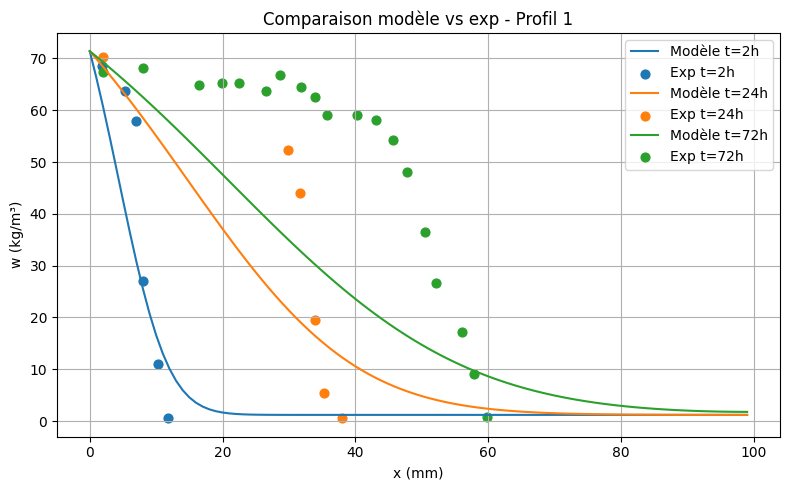

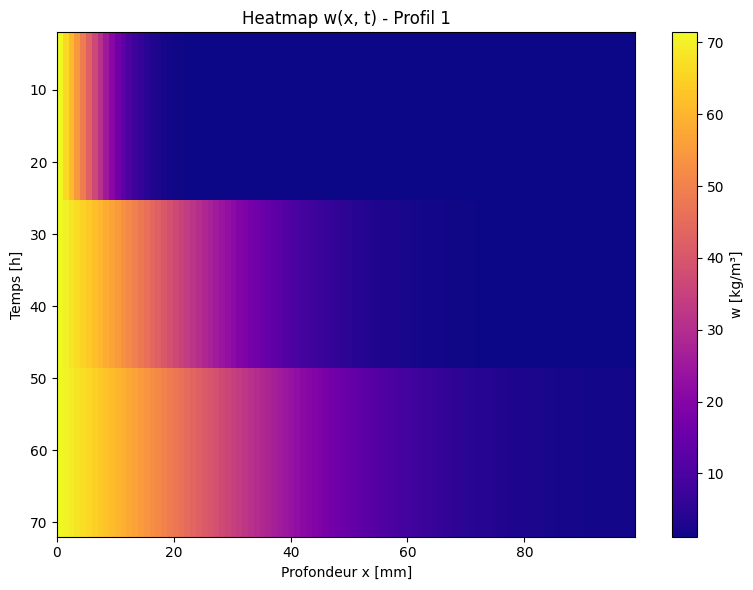


🧪 Profil 1: phi=0.11900000274181366, T=20.0, wc=0.44999998807907104, S0=0.6000000238418579


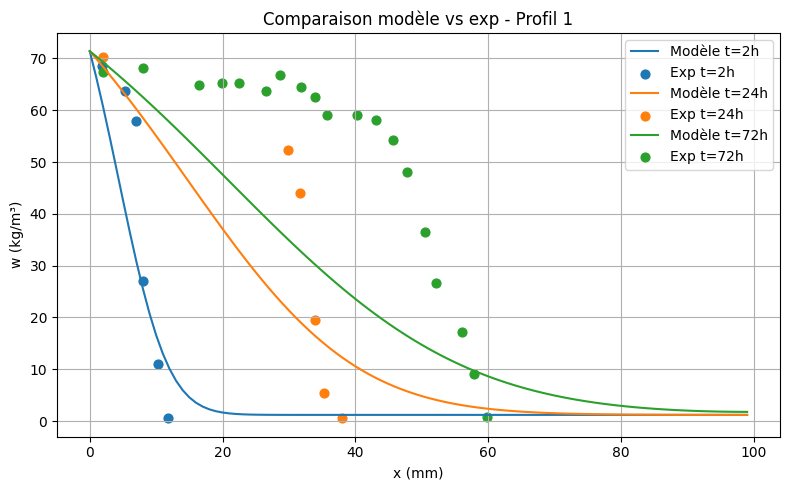

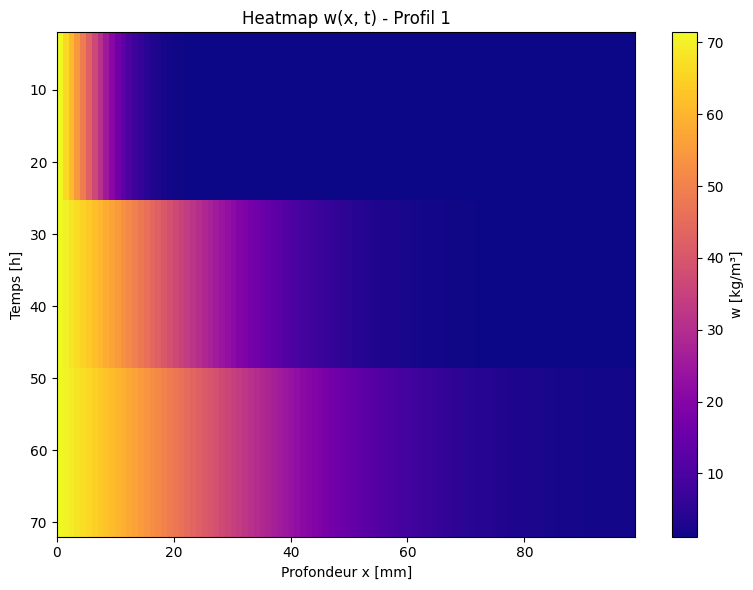

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

def plot_all_profiles(model, df_all, normalize, simulate_model_tf, extract_parameters, tf_linear_interp):
    input_columns = ['phi', 'T', 'w_c', 'S0']
    profils_uniques = df_all[input_columns].drop_duplicates().values.astype(np.float32)

    for idx, (phi, T, wc, S0) in enumerate(profils_uniques):
        subset = df_all[
            (df_all['phi'].round(4) == round(float(phi), 4)) &
            (df_all['T'] == float(T)) &
            (df_all['w_c'].round(4) == round(float(wc), 4)) &
            (df_all['S0'].round(4) == round(float(S0), 4))
        ]
        t_h_values = sorted(subset['t_h'].unique())

        if len(t_h_values) < 2:
            print(f"⚠️ Profil {idx+1}: pas assez de temps pour heatmap.")
            continue

        # 🔁 Simulations pour tous les temps
        Nx = 100
        dx = 1e-3
        dt = 30.0
        X_sim = []
        W_sim = []

        fig_curve, ax_curve = plt.subplots(figsize=(8, 5))
        print(f"\n🧪 Profil {idx+1}: phi={phi}, T={T}, wc={wc}, S0={S0}")

        for t_h in t_h_values:
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            norm_input = normalize(input_tensor)
            model_output = model(norm_input)
            Dv, alpha0, nShape = extract_parameters(model_output)

            x_model, w_model = simulate_model_tf(Dv, alpha0, nShape, S0, phi, 1000.0,
                                                 dx=dx, dt=dt, Tmax=float(t_h)*3600, Nx=Nx)
            X_sim.append(x_model.numpy() * 1000)  # en mm
            W_sim.append(w_model.numpy())

            # 📉 Courbe 1D pour comparaison à t donné
            group = subset[subset['t_h'] == t_h]
            x_exp = group['x_mm'].values
            w_exp = group['w_exp'].values
            if len(x_exp) < 3:
                continue

            ax_curve.plot(x_model.numpy() * 1000, w_model.numpy(), label=f"Modèle t={int(t_h)}h")
            ax_curve.scatter(x_exp, w_exp, label=f"Exp t={int(t_h)}h", s=40)

        ax_curve.set_title(f"Comparaison modèle vs exp - Profil {idx+1}")
        ax_curve.set_xlabel("x (mm)")
        ax_curve.set_ylabel("w (kg/m³)")
        ax_curve.grid()
        ax_curve.legend()
        plt.tight_layout()
        plt.show()

        # 🌡️ HEATMAP
        if len(W_sim) >= 2:
            fig_map, ax_map = plt.subplots(figsize=(8, 6))
            X_grid = np.array(X_sim)
            T_grid = np.array(t_h_values).reshape(-1, 1) * 3600  # secondes
            W_grid = np.array(W_sim)

            # Interpolation sur grille régulière (optionnel si X ne varie pas)
            im = ax_map.imshow(W_grid, aspect='auto', cmap='plasma',
                               extent=[X_grid[0].min(), X_grid[0].max(),
                                       T_grid.max()/3600, T_grid.min()/3600])

            ax_map.set_xlabel("Profondeur x [mm]")
            ax_map.set_ylabel("Temps [h]")
            ax_map.set_title(f"Heatmap w(x, t) - Profil {idx+1}")
            fig_map.colorbar(im, ax=ax_map, label="w [kg/m³]")
            plt.tight_layout()
            plt.show()
plot_all_profiles(model, df_all, normalize, simulate_model_tf, extract_parameters, tf_linear_interp)
# Fin du script
plot_all_profiles(model, df_all, normalize, simulate_model_tf, extract_parameters, tf_linear_interp)


In [22]:
%pip install keras-cyclical-learning-rate

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.optimizers import Adam
from clr_callback import CyclicalLearningRate

# 1. Chargement et normalisation
df_all = pd.read_csv("Dataset_multi-temps_format_.csv")
input_cols = ['phi','T','w_c','S0','t_h']
X = df_all[input_cols].drop_duplicates().values.astype(np.float32)
X_mean = tf.constant(X.mean(axis=0), dtype=tf.float32)
X_std  = tf.constant(X.std(axis=0),  dtype=tf.float32)
X_std_safe = tf.where(X_std==0, tf.ones_like(X_std), X_std)

def normalize(x):
    return (x - X_mean) / X_std_safe

def jitter_input(x, ε=0.02):
    return x + tf.random.normal(tf.shape(x), 0.0, ε)

# 2. Dataset mini‐batch & shuffle
batch_size = 8
ds = tf.data.Dataset.from_tensor_slices(X)
ds = ds.shuffle(buffer_size=len(X))
ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

# 3. Modèle avec Dropout
def build_ann_model():
    return Sequential([
        Input(shape=(5,)),
        Dense(64, activation='tanh'),
        Dropout(0.1),
        Dense(64, activation='tanh'),
        Dropout(0.1),
        Dense(3, activation='linear'),
    ])

model = build_ann_model()

# 4. Cyclical Learning Rate
clr = CyclicalLearningRate(
    initial_learning_rate=1e-4,
    maximal_learning_rate=1e-2,
    step_size=10 * (len(X) // batch_size),
    scale_fn=lambda x: 1.0,
    scale_mode="cycle"
)
optimizer = Adam(learning_rate=clr)

# 5. Entraînement par mini‐batch avec bruit sur les gradients
@tf.function
def train_step(batch):
    with tf.GradientTape() as tape:
        inp = normalize(batch)
        inp = jitter_input(inp, ε=0.02)
        out = model(inp, training=True)
        # ← ici : simulate_model_tf + loss réel
        loss = tf.reduce_mean(tf.square(out))  # placeholder

    grads = tape.gradient(loss, model.trainable_variables)
    noisy_grads = []
    for g in grads:
        if g is not None:
            noise = tf.random.normal(tf.shape(g), stddev=1e-3)
            noisy_grads.append(g + noise)
        else:
            noisy_grads.append(None)
    optimizer.apply_gradients(zip(noisy_grads, model.trainable_variables))
    return loss

# 6. Boucle d'entraînement
epochs = 50
for epoch in range(epochs):
    epoch_loss = 0.0
    steps = 0
    for batch in ds:
        loss = train_step(batch)
        epoch_loss += loss
        steps += 1
    print(f"Epoch {epoch+1}/{epochs} — Loss moyenne : {epoch_loss/steps:.4e}")


Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement keras-cyclical-learning-rate (from versions: none)
ERROR: No matching distribution found for keras-cyclical-learning-rate


ModuleNotFoundError: No module named 'clr_callback'

In [23]:
from sklearn.metrics import mean_squared_error, r2_score

# x_exp, w_exp : tes données expérimentales (1D arrays)
# x_model, w_model : tes sorties simulées (1D arrays, même discretisation)

# 1. Interpolation du modèle aux abscisses expérimentales
w_model_interp = np.interp(x_exp, x_model*1000, w_model)

# 2. RMSE et R²
rmse = np.sqrt(mean_squared_error(w_exp, w_model_interp))
r2   = r2_score(w_exp, w_model_interp)

print(f"Profil 1 → RMSE: {rmse:.2f} kg/m³, R²: {r2:.3f}")


ModuleNotFoundError: No module named 'sklearn'

In [19]:
# 🔧 FONCTION SIMULATE_MODEL_TF CORRIGÉE POUR LES TYPES

@tf.function
def simulate_model_tf_fixed(Dv, alpha0, nShape, S0, phi, rho_eau, dx, dt, Tmax, Nx, mode="imbibition"):
    # 🚨 CORRECTION CRITIQUE: Convertir TOUS les paramètres en tf.float32
    Dv = tf.cast(Dv, tf.float32)
    alpha0 = tf.cast(alpha0, tf.float32) 
    nShape = tf.cast(nShape, tf.float32)
    S0 = tf.cast(S0, tf.float32)
    phi = tf.cast(phi, tf.float32)
    rho_eau = tf.cast(rho_eau, tf.float32)
    dx = tf.cast(dx, tf.float32)
    dt = tf.cast(dt, tf.float32)
    Tmax = tf.cast(Tmax, tf.float32)
    Nx = tf.cast(Nx, tf.int32)

    Nt = tf.cast(tf.math.floordiv(Tmax, dt), tf.int32)
    x_vals = tf.linspace(0.0, dx * tf.cast(Nx - 1, tf.float32), Nx)

    # 🔧 Paramètres physiques (certains maintenant variables) - TOUS EN FLOAT32
    Sc = tf.constant(0.8, dtype=tf.float32)
    S_cap = tf.constant(0.75, dtype=tf.float32)
    beta = tf.constant(2.5, dtype=tf.float32)
    Pc0 = tf.constant(5e6, dtype=tf.float32)
    K_in = tf.constant(1.7e-20, dtype=tf.float32)
    eta_l = tf.constant(1e-3, dtype=tf.float32)

    # ✅ Initialisation de la saturation
    if mode == "imbibition":
        S = tf.ones((Nx,), dtype=tf.float32) * 0.01
        S = tf.tensor_scatter_nd_update(S, [[0]], [S0])
    elif mode == "drainage":
        S = tf.ones((Nx,), dtype=tf.float32) * S0
    else:
        raise ValueError("Mode must be 'imbibition' or 'drainage'")

    M = tf.ones((Nx,), dtype=tf.float32) * dx
    M = tf.tensor_scatter_nd_update(M, [[0], [Nx - 1]], [dx / 2, dx / 2])

    # 📈 Fonctions de diffusion avec paramètres variables
    def Dvapeur(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        fs = alpha0 + (1.0 - alpha0) / (1.0 + tf.pow((1.0 - S_val) / (1.0 - Sc), nShape))
        return tf.clip_by_value(fs, 1e-12, 10.0) * Dv

    def Dcapi(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        dpc = -beta * Pc0 * tf.pow(S_val, -beta - 1)
        return tf.abs(dpc) * K_in / eta_l

    def D_S(S_val):
        weight = tf.math.sigmoid(50.0 * (S_val - S_cap))
        return weight * Dcapi(S_val) + (1.0 - weight) * Dvapeur(S_val)

    # 🔁 Boucle temporelle
    for _ in tf.range(Nt):
        S_old = S
        for _ in tf.range(5):  # Picard simplifié
            D_vals = D_S(S)

            D_left = (D_vals[:-1] + D_vals[1:]) / 2.0
            fluxes = D_left * (S[1:] - S[:-1]) / dx

            dS_dt = tf.zeros_like(S)

            # 🌡️ Mise à jour des points intérieurs
            interior_flux = (fluxes[1:] - fluxes[:-1]) / dx
            dS_dt = tf.tensor_scatter_nd_add(
                dS_dt,
                tf.range(1, Nx - 1)[:, tf.newaxis],
                interior_flux
            )

            # ⚠️ Bord droit : Neumann ≈ 0
            last_flux = fluxes[-1] / dx
            dS_dt = tf.tensor_scatter_nd_add(dS_dt, [[Nx - 1]], [-last_flux])

            # 🔁 Mise à jour de S
            S = S_old + dt * dS_dt
            S = tf.tensor_scatter_nd_update(S, [[0]], [S0])  # Dirichlet

    # 🚨 CORRECTION CRITIQUE: S'assurer que tous les types sont cohérents
    w_final = tf.cast(phi, tf.float32) * tf.cast(rho_eau, tf.float32) * tf.cast(S, tf.float32)
    return x_vals, w_final



# ==========================================
# 1. CODE DE DIAGNOSTIC À AJOUTER
# ==========================================

# 🔍 Test de sensibilité des paramètres
def test_parameter_sensitivity(base_params, phi=0.119, S0=0.6, t_h=72):
    """Test l'impact de variations des paramètres sur la simulation"""
    Dv_base, alpha_base, n_base = base_params
    variations = [0.9, 0.95, 1.0, 1.05, 1.1]  # ±10% autour de la valeur de base
    
    print("🔬 Test de sensibilité des paramètres:")
    print(f"   Paramètres de base: D={Dv_base:.2e}, α={alpha_base:.4f}, n={n_base:.2f}")
    
    # Test sur D
    print("\n📊 Variation de D:")
    for factor in variations:
        D_test = Dv_base * factor
        x_model, w_model = simulate_model_tf_fixed(D_test, alpha_base, n_base, S0, phi, 1000.0,
                                           dx=1e-3, dt=30.0, Tmax=float(t_h)*3600.0, Nx=50)
        w_final_avg = tf.reduce_mean(w_model).numpy()
        print(f"   D={D_test:.2e} ({factor:.2f}x) → w_avg={w_final_avg:.1f}")
    
    # Test sur α
    print("\n📊 Variation de α:")
    for factor in variations:
        alpha_test = tf.clip_by_value(alpha_base * factor, 0.0015, 0.15)
        x_model, w_model = simulate_model_tf_fixed(Dv_base, alpha_test, n_base, S0, phi, 1000.0,
                                           dx=1e-3, dt=30.0, Tmax=float(t_h)*3600.0, Nx=50)
        w_final_avg = tf.reduce_mean(w_model).numpy()
        print(f"   α={alpha_test.numpy():.4f} ({factor:.2f}x) → w_avg={w_final_avg:.1f}")
    
    # Test sur n
    print("\n📊 Variation de n:")
    for factor in variations:
        n_test = tf.clip_by_value(n_base * factor, 1.2, 8.0)
        x_model, w_model = simulate_model_tf_fixed(Dv_base, alpha_base, n_test, S0, phi, 1000.0,
                                           dx=1e-3, dt=30.0, Tmax=float(t_h)*3600.0, Nx=50)
        w_final_avg = tf.reduce_mean(w_model).numpy()
        print(f"   n={n_test.numpy():.2f} ({factor:.2f}x) → w_avg={w_final_avg:.1f}")

# 📈 Analyse des gradients
def analyze_gradients(model, df_all, normalize, simulate_model_tf_fixed, tf_linear_interp, extract_parameters):
    """Analyse la magnitude des gradients pour chaque paramètre"""
    unique_inputs = df_all[['phi', 'T', 'w_c', 'S0', 't_h']].drop_duplicates().values[:3]  # 3 premiers profils
    
    gradient_stats = {'D': [], 'alpha': [], 'n': []}
    
    for i, (phi, T, wc, S0, t_h) in enumerate(unique_inputs):
        print(f"\n🔍 Analyse gradients profil {i+1}: t_h={t_h}h")
        
        with tf.GradientTape() as tape:
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            norm_input = normalize(input_tensor)
            model_output = model(norm_input)
            Dv, alpha0, nShape = extract_parameters(model_output)
            
            # Simuler pour ce profil
            group = df_all[
                (df_all['phi'].round(4) == round(float(phi), 4)) &
                (df_all['T'] == T) &
                (df_all['w_c'].round(4) == round(float(wc), 4)) &
                (df_all['S0'].round(4) == round(float(S0), 4)) &
                (df_all['t_h'] == t_h)
            ]
            
            if len(group) < 3:
                continue
                
            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))
            
            x_model, w_model = simulate_model_tf_fixed(Dv, alpha0, nShape, S0, phi, 1000.0,
                                               dx=1e-3, dt=30.0, Tmax=float(t_h)*3600.0, Nx=50)
            
            w_interp = tf_linear_interp(x_model, w_model, x_exp)
            loss = tf.reduce_mean(tf.square(w_interp - w_exp))
        
        # Calculer les gradients
        grads = tape.gradient(loss, model.trainable_variables)
        
        # Analyser les gradients par couche (approximation pour D, α, n)
        if grads[-1] is not None:  # Dernière couche (sortie)
            grad_output = grads[-1]  # Gradients de la couche de sortie [3 unités]
            
            grad_D = tf.reduce_mean(tf.abs(grad_output[:, 0])).numpy()
            grad_alpha = tf.reduce_mean(tf.abs(grad_output[:, 1])).numpy()
            grad_n = tf.reduce_mean(tf.abs(grad_output[:, 2])).numpy()
            
            gradient_stats['D'].append(grad_D)
            gradient_stats['alpha'].append(grad_alpha)
            gradient_stats['n'].append(grad_n)
            
            print(f"   |∇D| = {grad_D:.2e}")
            print(f"   |∇α| = {grad_alpha:.2e}")
            print(f"   |∇n| = {grad_n:.2e}")
    
    # Résumé
    print("\n📊 RÉSUMÉ DES GRADIENTS:")
    for param, grads in gradient_stats.items():
        if grads:
            print(f"   {param}: moyenne={np.mean(grads):.2e}, std={np.std(grads):.2e}")

# 🎲 Test avec différentes initialisations
def test_multiple_initializations(df_all, n_tests=3):
    """Teste plusieurs initialisations aléatoires"""
    results = []
    
    for test_id in range(n_tests):
        print(f"\n🎲 Test d'initialisation {test_id + 1}/{n_tests}")
        
        # Nouveau modèle avec initialisation aléatoire différente
        tf.random.set_seed(42 + test_id * 100)  # Seed différent
        model_test = build_ann_model()
        optimizer_test = Adam(learning_rate=1e-4)  # Learning rate réduit
        
        # Quelques époques d'entraînement
        for epoch in range(5):
            mean_loss, mean_params = train_epoch(
                model_test, df_all, optimizer_test, normalize,
                simulate_model_tf_fixed, tf_linear_interp, extract_parameters,
                Nx=40, dx=1e-3, dt=60.0
            )
            
            if mean_loss is None:
                break
                
            if epoch == 4:  # Dernière époque
                results.append({
                    'test_id': test_id,
                    'final_loss': mean_loss,
                    'final_D': mean_params['Dv'],
                    'final_alpha': mean_params['alpha'],
                    'final_n': mean_params['n']
                })
                print(f"   Résultats finaux: Loss={mean_loss:.4e}")
                print(f"   D={mean_params['Dv']:.2e}, α={mean_params['alpha']:.4f}, n={mean_params['n']:.2f}")
    
    return results

# ==========================================
# 2. MODIFICATIONS À APPORTER AU CODE PRINCIPAL
# ==========================================

# MODIFICATION 1: Fonction extract_parameters avec les nouvelles contraintes
def extract_parameters_fixed(model_output):
    """Version corrigée avec vos nouvelles contraintes"""
    if tf.reduce_any(tf.math.is_nan(model_output)):
        print("⚠️ NaN détecté dans model_output")
        return tf.constant(1e-8, dtype=tf.float32), tf.constant(0.01, dtype=tf.float32), tf.constant(2.0, dtype=tf.float32)
    
    # Correction: Indexing for both 2D ([1, 3]) and 1D ([3]) tensors
    if len(model_output.shape) == 2 and model_output.shape[0] == 1:
        D_raw = model_output[0, 0]
        alpha_raw = model_output[0, 1]
        n_raw = model_output[0, 2]
    elif len(model_output.shape) == 1 and model_output.shape[0] == 3:
        D_raw = model_output[0]
        alpha_raw = model_output[1]
        n_raw = model_output[2]
    else:
        raise ValueError(f"extract_parameters_fixed: Unexpected model_output shape {model_output.shape}")
    
    # Contraintes physiques ajustées selon vos spécifications :
    # D : 1e-9 à 1e-6 m²/s 
    D_raw_clipped = tf.clip_by_value(D_raw, -10.0, 10.0)
    Dv = tf.clip_by_value(tf.nn.softplus(D_raw_clipped) * 1e-6 + 1e-9, 1e-9, 1e-6)
    
    # α : 0.0015 à 0.15 
    alpha_raw_clipped = tf.clip_by_value(alpha_raw, -10.0, 10.0)
    alpha0 = tf.clip_by_value(tf.nn.sigmoid(alpha_raw_clipped) * 0.1485 + 0.0015, 0.0015, 0.15)
    
    # n : 1.2 à 8.0 
    n_raw_clipped = tf.clip_by_value(n_raw, -10.0, 10.0)
    nShape = tf.clip_by_value(tf.nn.softplus(n_raw_clipped) * 0.8 + 1.2, 1.2, 8.0)
    
    # Vérification finale des NaN
    Dv_safe = tf.where(tf.math.is_nan(Dv), tf.constant(1e-8, dtype=tf.float32), Dv)
    alpha0_safe = tf.where(tf.math.is_nan(alpha0), tf.constant(0.01, dtype=tf.float32), alpha0)
    nShape_safe = tf.where(tf.math.is_nan(nShape), tf.constant(2.0, dtype=tf.float32), nShape)
    
    return Dv_safe, alpha0_safe, nShape_safe

# MODIFICATION 2: Learning rate plus bas et architecture plus stable
def build_ann_model_improved(input_dim=5):
    """Modèle avec initialisation plus conservative"""
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(15, activation='tanh', kernel_initializer='glorot_normal'),  # Plus petit
        Dense(15, activation='tanh', kernel_initializer='glorot_normal'),
        Dense(3, activation='linear', kernel_initializer='zeros')  # Initialisation à zéro
    ])
    return model

# MODIFICATION 3: Optimizer avec learning rate adaptatif
def create_adaptive_optimizer():
    """Optimizer avec learning rate qui décroît"""
    initial_learning_rate = 1e-4
    lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate,
        decay_steps=10,
        decay_rate=0.95,
        staircase=True
    )
    return Adam(learning_rate=lr_schedule)

# MODIFICATION 4: Fonction d'entraînement avec monitoring amélioré
def train_epoch_improved(model, df_all, optimizer, normalize, simulate_model_tf, tf_linear_interp, 
                        extract_parameters, Nx=50, dx=1e-3, dt=30.0):
    """Version améliorée avec monitoring des gradients"""
    
    unique_inputs = (
        df_all[['phi', 'T', 'w_c', 'S0', 't_h']]
        .round(4)
        .drop_duplicates()
        .values.astype(np.float32)
    )

    total_loss = 0.0
    valid_count = 0
    param_epoch_vals = {'Dv': [], 'alpha': [], 'n': []}
    gradient_norms = []

    with tf.GradientTape() as tape:
        for i in range(len(unique_inputs)):
            phi, T, wc, S0, t_h = unique_inputs[i]
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            
            norm_input = normalize(input_tensor)
            if tf.reduce_any(tf.math.is_nan(norm_input)):
                continue
                
            model_output = model(norm_input)
            if tf.reduce_any(tf.math.is_nan(model_output)):
                continue
                
            Dv, alpha0, nShape = extract_parameters(model_output)

            phi_f, T_f, wc_f, S0_f, t_h_f = map(float, [phi, T, wc, S0, t_h])
            group = df_all[
                (df_all['phi'].round(4) == round(phi_f, 4)) &
                (df_all['T'] == T_f) &
                (df_all['w_c'].round(4) == round(wc_f, 4)) &
                (df_all['S0'].round(4) == round(S0_f, 4)) &
                (df_all['t_h'] == t_h_f)
            ]

            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            if len(x_exp) < 3:
                continue

            w_exp_mean = tf.reduce_mean(w_exp)
            w_exp_std = tf.math.reduce_std(w_exp)
            if tf.math.is_nan(w_exp_std) or w_exp_std < 1e-8:
                continue

            try:
                x_model, w_model = simulate_model_tf(Dv, alpha0, nShape, S0, phi, 1000.0, 
                                                     dx, dt, float(t_h) * 3600.0, Nx)
                if tf.reduce_any(tf.math.is_nan(w_model)):
                    continue
            except:
                continue
                
            x_exp_clip = tf.clip_by_value(x_exp * 1e-3, x_model[0], x_model[-1]) * 1e3
            w_interp = tf_linear_interp(x_model, w_model, x_exp_clip)

            w_exp_norm = (w_exp - w_exp_mean) / (w_exp_std + 1e-12)
            w_interp_norm = (w_interp - w_exp_mean) / (w_exp_std + 1e-12)

            if tf.reduce_any(tf.math.is_nan(w_interp_norm)):
                continue

            loss = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
            if tf.math.is_nan(loss):
                continue

            total_loss += loss
            valid_count += 1
            param_epoch_vals['Dv'].append(Dv.numpy())
            param_epoch_vals['alpha'].append(alpha0.numpy())
            param_epoch_vals['n'].append(nShape.numpy())

        if valid_count == 0:
            return None, None, None

        mean_loss = total_loss / valid_count

    # Calcul et analyse des gradients
    grads = tape.gradient(mean_loss, model.trainable_variables)
    
    # Calcul de la norme des gradients
    grad_norm = tf.linalg.global_norm([g for g in grads if g is not None])
    gradient_norms.append(grad_norm.numpy())
    
    # Gradient clipping plus doux
    grads = [tf.clip_by_value(g, -0.1, 0.1) if g is not None else None for g in grads]
    
    # Vérification des NaN dans les gradients
    grads_clean = []
    for g in grads:
        if g is not None and tf.reduce_any(tf.math.is_nan(g)):
            grads_clean.append(tf.zeros_like(g))
        else:
            grads_clean.append(g)
    
    optimizer.apply_gradients(zip(grads_clean, model.trainable_variables))

    mean_params = {k: np.mean(v) if v else 0.0 for k, v in param_epoch_vals.items()}
    return mean_loss.numpy(), mean_params, np.mean(gradient_norms)

# ==========================================
# 3. SCRIPT D'EXÉCUTION DES DIAGNOSTICS
# ==========================================

print("🔍 DÉBUT DES DIAGNOSTICS\n")

# Test 1: Sensibilité des paramètres avec le modèle actuel
print("=" * 50)
print("TEST 1: SENSIBILITÉ DES PARAMÈTRES")
print("=" * 50)

# Obtenir des paramètres du modèle actuel
test_input = tf.constant([[0.119, 20.0, 0.45, 0.6, 72.0]], dtype=tf.float32)
model_output = model(normalize(test_input))
base_params = extract_parameters(model_output)
test_parameter_sensitivity(base_params)

# Test 2: Analyse des gradients
print("\n" + "=" * 50)
print("TEST 2: ANALYSE DES GRADIENTS")
print("=" * 50)
analyze_gradients(model, df_all, normalize, simulate_model_tf_fixed, tf_linear_interp, extract_parameters)

# Test 3: Différentes initialisations
print("\n" + "=" * 50)
print("TEST 3: DIFFÉRENTES INITIALISATIONS")
print("=" * 50)
init_results = test_multiple_initializations(df_all, n_tests=3)

# Affichage des résultats d'initialisation
if init_results:
    print("\n📊 COMPARAISON DES INITIALISATIONS:")
    for result in init_results:
        print(f"   Test {result['test_id']}: Loss={result['final_loss']:.4e}")
        print(f"      D={result['final_D']:.2e}, α={result['final_alpha']:.4f}, n={result['final_n']:.2f}")

print("\n🎉 DIAGNOSTICS TERMINÉS")

🔍 DÉBUT DES DIAGNOSTICS

TEST 1: SENSIBILITÉ DES PARAMÈTRES
🔬 Test de sensibilité des paramètres:
   Paramètres de base: D=1.21e-08, α=0.0929, n=1.39

📊 Variation de D:
   D=1.09e-08 (0.90x) → w_avg=44.6
   D=1.15e-08 (0.95x) → w_avg=45.7
   D=1.21e-08 (1.00x) → w_avg=46.8
   D=1.27e-08 (1.05x) → w_avg=47.9
   D=1.33e-08 (1.10x) → w_avg=48.9

📊 Variation de α:
   α=0.0836 (0.90x) → w_avg=46.2
   α=0.0882 (0.95x) → w_avg=46.5
   α=0.0929 (1.00x) → w_avg=46.8
   α=0.0975 (1.05x) → w_avg=47.1
   α=0.1022 (1.10x) → w_avg=47.4

📊 Variation de n:
   n=1.26 (0.90x) → w_avg=48.4
   n=1.32 (0.95x) → w_avg=47.6
   n=1.39 (1.00x) → w_avg=46.8
   n=1.46 (1.05x) → w_avg=46.0
   n=1.53 (1.10x) → w_avg=45.3

TEST 2: ANALYSE DES GRADIENTS

🔍 Analyse gradients profil 1: t_h=2.0h


InvalidArgumentError: {{function_node __wrapped__StridedSlice_device_/job:localhost/replica:0/task:0/device:CPU:0}} Index out of range using input dim 1; input has only 1 dims [Op:StridedSlice] name: strided_slice/

In [ ]:
# === 3. Modèle ANN ===
def build_ann_model(input_dim=5):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(16, activation='tanh'), # 32 neurones cachés avec activation tanh
        Dense(16, activation='tanh'),
        Dense(1, activation='linear')  # Dv sera activé via softplus ensuite
    ])
    return model

model = build_ann_model()
optimizer = Adam(learning_rate=1e-3)

In [ ]:
@tf.function
def simulate_model_tf(Dv, S0, phi, rho_eau, dx, dt, Tmax, Nx, mode="imbibition"):
    # Convertir tous les scalaires en tf.Tensor
    dx = tf.convert_to_tensor(dx, dtype=tf.float32)
    dt = tf.convert_to_tensor(dt, dtype=tf.float32)
    Tmax = tf.convert_to_tensor(Tmax, dtype=tf.float32)
    Nx = tf.convert_to_tensor(Nx, dtype=tf.int32)

    Nt = tf.cast(tf.math.floordiv(Tmax, dt), tf.int32)
    x_vals = tf.linspace(0.0, dx * tf.cast(Nx - 1, tf.float32), Nx)

    # 🔧 Paramètres physiques
    alpha0 = 0.005
    Sc = 0.8
    nShape = 5
    S_cap = 0.75
    beta = 2.5
    Pc0 = 5e6
    K_in = 1.7e-20
    eta_l = 1e-3

    # ✅ Initialisation de la saturation
    if mode == "imbibition":
        S = tf.ones((Nx,), dtype=tf.float32) * 0.01
        S = tf.tensor_scatter_nd_update(S, [[0]], [S0])
    elif mode == "drainage":
        S = tf.ones((Nx,), dtype=tf.float32) * S0
    else:
        raise ValueError("Mode must be 'imbibition' or 'drainage'")

    M = tf.ones((Nx,), dtype=tf.float32) * dx
    M = tf.tensor_scatter_nd_update(M, [[0], [Nx - 1]], [dx / 2, dx / 2])

    # 📈 Fonctions de diffusion
    def Dvapeur(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        fs = alpha0 + (1.0 - alpha0) / (1.0 + tf.pow((1.0 - S_val) / (1.0 - Sc), nShape))
        return tf.clip_by_value(fs, 1e-12, 10.0) * Dv

    def Dcapi(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        dpc = -beta * Pc0 * tf.pow(S_val, -beta - 1)
        return tf.abs(dpc) * K_in / eta_l

    def D_S(S_val):
        weight = tf.math.sigmoid(50.0 * (S_val - S_cap))
        return weight * Dcapi(S_val) + (1.0 - weight) * Dvapeur(S_val)

    # 🔁 Boucle temporelle
    for _ in tf.range(Nt):
        S_old = S
        for _ in tf.range(5):  # Picard simplifié
            D_vals = D_S(S)

            D_left = (D_vals[:-1] + D_vals[1:]) / 2.0
            fluxes = D_left * (S[1:] - S[:-1]) / dx

            dS_dt = tf.zeros_like(S)

            # 🌡️ Mise à jour des points intérieurs
            interior_flux = (fluxes[1:] - fluxes[:-1]) / dx
            dS_dt = tf.tensor_scatter_nd_add(
                dS_dt,
                tf.range(1, Nx - 1)[:, tf.newaxis],
                interior_flux
            )

            # ⚠️ Bord droit : Neumann ≈ 0
            last_flux = fluxes[-1] / dx
            dS_dt = tf.tensor_scatter_nd_add(dS_dt, [[Nx - 1]], [-last_flux])

            # 🔁 Mise à jour de S
            S = S_old + dt * dS_dt
            S = tf.tensor_scatter_nd_update(S, [[0]], [S0])  # Dirichlet

    w_final = phi * rho_eau * S
    return x_vals, w_final


In [ ]:
# === 5. Interpolation ===
@tf.function
def tf_linear_interp(x_known, y_known, x_interp):
    x_interp_m = x_interp * 1e-3
    indices = tf.searchsorted(x_known, x_interp_m, side='right') - 1
    indices = tf.clip_by_value(indices, 0, tf.shape(x_known)[0] - 2)
    x0 = tf.gather(x_known, indices)
    x1 = tf.gather(x_known, indices + 1)
    y0 = tf.gather(y_known, indices)
    y1 = tf.gather(y_known, indices + 1)
    return y0 + (y1 - y0) * (x_interp_m - x0) / (x1 - x0 + 1e-12)

In [ ]:
# === 6. Courbes expérimentales ===
x_exp = tf.constant(np.linspace(2, 60, 30), dtype=tf.float32)  # mm
w_exp_all = [tf.constant(np.random.normal(60 - xi, 2.0, size=30), dtype=tf.float32) for xi in x_exp]  # mock

w_exp_mean = tf.reduce_mean(w_exp_all[0])
w_exp_std = tf.math.reduce_std(w_exp_all[0])

In [ ]:
def compute_loss(model, df_all):
    def create_key(df):
        return df.apply(lambda row: f"{row['phi']:.5f}_{row['T']:.1f}_{row['w_c']:.5f}_{row['S0']:.5f}_{int(row['t_h'])}", axis=1)

    if 'key' not in df_all.columns:
        df_all['key'] = create_key(df_all)

    mse_list = []
    skipped = 0

    for key in df_all['key'].unique():
        group = df_all[df_all['key'] == key]
        if group.empty:
            print(f"⚠️ Profil introuvable pour la clé : {key}")
            skipped += 1
            continue

        try:
            # 🔁 Extraire les paramètres du profil
            phi = group['phi'].iloc[0]
            T = group['T'].iloc[0]
            wc = group['w_c'].iloc[0]
            S0 = group['S0'].iloc[0]
            t_h = group['t_h'].iloc[0]

            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            if len(x_exp) == 0:
                print(f"❌ Profil vide pour : {key}")
                skipped += 1
                continue

            w_mean = tf.reduce_mean(w_exp)
            w_std = tf.math.reduce_std(w_exp)

            if w_std.numpy() == 0.0:
                print(f"⚠️ w_exp_std = 0 pour {key}, ignoré")
                skipped += 1
                continue

            # 🔎 Entrée du modèle
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            norm_input = normalize(input_tensor)

            if tf.reduce_any(tf.math.is_nan(norm_input)):
                print(f"❌ NaN dans l'entrée normalisée, profil {key}")
                skipped += 1
                continue

            D0 = model(norm_input)
            if tf.reduce_any(tf.math.is_nan(D0)):
                print(f"❌ D0 = NaN pour {key}")
                skipped += 1
                continue

            Dv = tf.clip_by_value(tf.squeeze(tf.nn.softplus(D0) * 1e-7), 1e-10, 5e-8)

            x_model, w_model = simulate_model_tf(Dv, S0, phi, 1000.0,
                                                 dx=1e-3, dt=30.0, Tmax=t_h * 3600, Nx=100)

            x_min = tf.reduce_min(x_model)
            x_max = tf.reduce_max(x_model)
            x_exp_clipped = tf.clip_by_value(x_exp * 1e-3, x_min, x_max) * 1e3

            w_interp = tf_linear_interp(x_model, w_model, x_exp_clipped)
            w_interp_norm = (w_interp - w_mean) / (w_std + 1e-12)
            w_exp_norm = (w_exp - w_mean) / (w_std + 1e-12)

            if tf.reduce_any(tf.math.is_nan(w_interp_norm)) or tf.reduce_any(tf.math.is_nan(w_exp_norm)):
                print(f"❌ NaN dans les profils normalisés {key}")
                skipped += 1
                continue

            mse = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
            mse_list.append(mse)

        except Exception as e:
            print(f"🚨 Erreur inattendue dans le profil {key} : {e}")
            skipped += 1
            continue

    if not mse_list:
        print("❌ Aucune donnée exploitable.")
        return tf.constant(float('nan'), dtype=tf.float32)

    print(f"✅ Profils utilisés : {len(mse_list)} / {len(df_all['key'].unique())}, ignorés : {skipped}")
    return tf.reduce_mean(mse_list)


In [ ]:
def debug_all_profiles(model, df_all):
    input_columns = ['phi', 'T', 'w_c', 'S0', 't_h']
    profiles = df_all[input_columns].drop_duplicates().values.astype(np.float32)

    for i, row in enumerate(profiles):
        phi, T, wc, S0, t_h = row
        print(f"\n🔎 Profil {i+1}: phi={phi}, T={T}, wc={wc}, S0={S0}, t_h={t_h}")

        try:
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            norm_input = normalize(input_tensor)

            # Check normalization
            if tf.math.reduce_any(tf.math.is_nan(norm_input)):
                print("❌ NaN dans l'entrée normalisée !")
                continue

            D0 = model(norm_input)
            if tf.math.reduce_any(tf.math.is_nan(D0)):
                print("❌ D0 prédit est NaN !")
                continue

            Dv = tf.squeeze(tf.nn.softplus(D0) * 1e-7)
            print(f"✅ D0 = {D0.numpy().squeeze():.2e} → Dv = {Dv.numpy():.2e}")

            group = df_all[
                (df_all['phi'] == phi) &
                (df_all['T'] == T) &
                (df_all['w_c'] == wc) &
                (df_all['S0'] == S0) &
                (df_all['t_h'] == t_h)
            ]
            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            w_mean = tf.reduce_mean(w_exp)
            w_std = tf.math.reduce_std(w_exp)

            if w_std.numpy() == 0.0:
                print("⚠️ Écart-type nul pour w_exp !")
                continue

            x_model, w_model = simulate_model_tf(Dv, S0, phi, 1000.0,
                                                 dx=1e-3, dt=30.0, Tmax=t_h*3600, Nx=50)
            w_interp = tf_linear_interp(x_model, w_model, x_exp)
            w_interp_norm = (w_interp - w_mean) / w_std
            w_exp_norm = (w_exp - w_mean) / w_std

            mse = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
            print(f"📉 Loss MSE pour ce profil : {mse.numpy():.4e}")

        except Exception as e:
            print("🚨 Erreur pendant le calcul :", e)


In [ ]:
debug_all_profiles(model, df_all)


In [ ]:
input_tensor = tf.convert_to_tensor([[0.119, 20.0, 0.45, 0.6, 72.0]], dtype=tf.float32)
D0 = model(normalize(input_tensor))
Dv = tf.clip_by_value(tf.squeeze(tf.nn.softplus(D0) * 1e-7), 1e-10, 5e-8)

x_model, w_model = simulate_model_tf(Dv, 0.6, 0.119, 1000.0, dx=1e-3, dt=30.0, Tmax=72*3600, Nx=100)

import matplotlib.pyplot as plt
plt.plot(x_model.numpy()*1000, w_model.numpy(), label="Simulation")
plt.title("Test manuel d’un profil à 72h")
plt.xlabel("x [mm]")
plt.ylabel("w [kg/m³]")
plt.grid()
plt.legend()
plt.show()


In [ ]:
# 🧪 Extraire un seul profil expérimental pour t = 72h (ou 2h ou 24h)
profil_test = df_all[(df_all['t_h'] == 72.0)]

if profil_test.empty:
    print("❌ Aucun profil trouvé pour t_h = 72.0h")
else:
    phi = profil_test['phi'].iloc[0]
    T = profil_test['T'].iloc[0]
    wc = profil_test['w_c'].iloc[0]
    S0 = profil_test['S0'].iloc[0]
    t_h = profil_test['t_h'].iloc[0]

    x_exp = tf.constant(profil_test['x_mm'].values.astype(np.float32))
    w_exp = tf.constant(profil_test['w_exp'].values.astype(np.float32))

    w_mean = tf.reduce_mean(w_exp)
    w_std = tf.math.reduce_std(w_exp)

    print("📊 Taille données exp :", len(x_exp.numpy()), "std:", w_std.numpy())

    if tf.math.is_nan(w_std) or w_std.numpy() == 0.0:
        print("⚠️ w_exp_std = 0 ou NaN, arrêt.")
    else:
        input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
        input_norm = normalize(input_tensor)

        if tf.reduce_any(tf.math.is_nan(input_norm)):
            print("❌ NaN dans entrée normalisée")
        else:
            D0 = model(input_norm)
            Dv = tf.clip_by_value(tf.squeeze(tf.nn.softplus(D0) * 1e-7), 1e-10, 5e-8)
            print("✅ Dv simulé :", Dv.numpy())

            x_model, w_model = simulate_model_tf(Dv, S0, tf.convert_to_tensor(phi, dtype=tf.float32), 1000.0,
                                                 dx=1e-3, dt=30.0, Tmax=float(t_h)*3600, Nx=100)

            print("📏 x_model range :", x_model.numpy()[0]*1000, "→", x_model.numpy()[-1]*1000)
            print("📏 x_exp range   :", x_exp.numpy()[0], "→", x_exp.numpy()[-1])

            x_exp_clip = tf.clip_by_value(x_exp * 1e-3, x_model[0], x_model[-1]) * 1e3
            w_interp = tf_linear_interp(x_model, w_model, x_exp_clip)

            w_exp_norm = (w_exp - w_mean) / (w_std + 1e-12)
            w_interp_norm = (w_interp - w_mean) / (w_std + 1e-12)

            if tf.reduce_any(tf.math.is_nan(w_interp_norm)):
                print("❌ NaN dans w_interp_norm")
            else:
                loss = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
                print("✅ LOSS TEST =", loss.numpy())

                # 🔍 Plot pour valider visuellement
                import matplotlib.pyplot as plt
                plt.plot(x_model.numpy()*1000, w_model.numpy(), label="Simulation")
                plt.plot(x_exp.numpy(), w_exp.numpy(), 'o', label="Expérimental")
                plt.legend()
                plt.title("Profil test à t = 72h")
                plt.grid()
                plt.show()


In [ ]:
def train_epoch(model, df_all, optimizer, normalize, simulate_model_tf, tf_linear_interp, Nx=50, dx=1e-3, dt=30.0):
    import tensorflow as tf
    import numpy as np

    unique_inputs = (
        df_all[['phi', 'T', 'w_c', 'S0', 't_h']]
        .round(4)
        .drop_duplicates()
        .values.astype(np.float32)
    )

    total_loss = 0.0
    valid_count = 0
    D0_epoch_vals = []

    with tf.GradientTape() as tape:
        for i in range(len(unique_inputs)):
            phi, T, wc, S0, t_h = unique_inputs[i]
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            D0 = model(normalize(input_tensor))
            Dv = tf.squeeze(tf.nn.softplus(D0) * 1e-7)

            phi_f, T_f, wc_f, S0_f, t_h_f = map(float, [phi, T, wc, S0, t_h])
            group = df_all[
                (df_all['phi'].round(4) == round(phi_f, 4)) &
                (df_all['T'] == T_f) &
                (df_all['w_c'].round(4) == round(wc_f, 4)) &
                (df_all['S0'].round(4) == round(S0_f, 4)) &
                (df_all['t_h'] == t_h_f)
            ]

            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            print(f"\n🔎 Profil {i+1}/{len(unique_inputs)}: phi={phi}, T={T}, wc={wc}, S0={S0}, t_h={t_h}")
            print("📊 Nombre de points trouvés :", len(group))
            print(group[['x_mm', 'w_exp']])

            if len(x_exp) < 3:
                print("❌ Trop peu de points pour profil :", t_h)
                continue

            w_exp_mean = tf.reduce_mean(w_exp)
            w_exp_std = tf.math.reduce_std(w_exp)
            if tf.math.is_nan(w_exp_std) or w_exp_std < 1e-8:
                print(f"❌ Rejeté : std(w_exp) = {w_exp_std.numpy()}")
                continue

            x_model, w_model = simulate_model_tf(Dv, S0, phi, 1000.0, dx, dt, t_h * 3600.0, Nx)
            x_exp_clip = tf.clip_by_value(x_exp * 1e-3, x_model[0], x_model[-1]) * 1e3
            w_interp = tf_linear_interp(x_model, w_model, x_exp_clip)

            w_exp_norm = (w_exp - w_exp_mean) / (w_exp_std + 1e-12)
            w_interp_norm = (w_interp - w_exp_mean) / (w_exp_std + 1e-12)

            if tf.reduce_any(tf.math.is_nan(w_interp_norm)):
                print("❌ Rejeté : NaN dans w_interp_norm")
                continue

            loss = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
            if tf.math.is_nan(loss):
                print("❌ Rejeté : NaN dans le loss")
                continue

            print("✅ Profil accepté. Loss =", loss.numpy())

            total_loss += loss
            valid_count += 1
            D0_epoch_vals.append(D0.numpy()[0][0])

        if valid_count == 0:
            print("❌ Aucun profil valide → arrêt.")
            return None, None

        mean_loss = total_loss / valid_count

    grads = tape.gradient(mean_loss, model.trainable_variables)
    grads = [tf.clip_by_value(g, -1.0, 1.0) if g is not None else None for g in grads]
    optimizer.apply_gradients(zip(grads, model.trainable_variables))

    return mean_loss.numpy(), np.mean(D0_epoch_vals)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

loss_history = []
D0_history = []

for epoch in range(100):
    mean_loss, mean_D0 = train_epoch(
        model, df_all, optimizer, normalize,
        simulate_model_tf, tf_linear_interp,
        Nx=50, dx=1e-3, dt=30.0
    )

    if mean_loss is None:
        print(f"Epoch {epoch}: ❌ Aucun profil valide → entraînement arrêté.")
        break

    loss_history.append(mean_loss)
    D0_history.append(mean_D0)

    if epoch % 10 == 0:
        print(f"📉 Epoch {epoch}, Loss: {mean_loss:.4e}, D0 mean: {mean_D0:.4e}")
        model.save_weights(f"model_checkpoint_epoch{epoch}.weights.h5")  # 💾 Sauvegarde du modèle
        np.save("loss_history.npy", loss_history)
        np.save("D0_history.npy", D0_history)

# 🎯 Graphe de convergence
plt.figure(figsize=(8, 4))
plt.plot(loss_history, label="Loss", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Convergence du modèle")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
Dv_test = tf.constant(1e-8, dtype=tf.float32)
x_model, w_model = simulate_model_tf(Dv_test, 0.6, 0.119, 1000.0, dx=1e-3, dt=30.0, Tmax=72*3600, Nx=100)

print("x_model (mm):", x_model.numpy() * 1000)
print("w_model:", w_model.numpy())


In [ ]:
print("x_exp (mm):", x_exp.numpy())
print("x_exp range:", tf.reduce_min(x_exp).numpy(), "→", tf.reduce_max(x_exp).numpy())
print("x_model range:", x_model.numpy()[0] * 1000, "→", x_model.numpy()[-1] * 1000)


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 🔍 Trouver le dernier fichier de poids sauvegardé
checkpoints = [f for f in os.listdir() if f.startswith("model_checkpoint_epoch") and f.endswith(".weights.h5")]
if not checkpoints:
    raise ValueError("❌ Aucun fichier .weights.h5 trouvé.")

# 🔢 Extraire le numéro d'epoch et trier
checkpoints_sorted = sorted(checkpoints, key=lambda x: int(x.split("epoch")[1].split(".")[0]))
last_checkpoint = checkpoints_sorted[-1]
print(f"📂 Chargement du modèle depuis : {last_checkpoint}")

# ✅ Charger les poids
model.load_weights(last_checkpoint)

# 📈 Afficher loss et D0
loss_history = np.load("loss_history.npy")
D0_history = np.load("D0_history.npy")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(loss_history, label="Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("📉 Courbe de loss")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(D0_history, label="D0 moyen")
plt.xlabel("Epoch")
plt.ylabel("D0 estimé")
plt.title("📈 D0 moyen par epoch")
plt.grid(True)

plt.tight_layout()
plt.show()

# 🔁 Affichage des courbes prédictions vs expérimental
unique_inputs = (
    df_all[['phi', 'T', 'w_c', 'S0', 't_h']]
    .round(4)
    .drop_duplicates()
    .values.astype(np.float32)
)

for i in range(len(unique_inputs)):
    phi, T, wc, S0, t_h = unique_inputs[i]
    input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
    D0 = model(normalize(input_tensor))
    Dv = tf.squeeze(tf.nn.softplus(D0) * 1e-7)

    group = df_all[
        (df_all['phi'].round(4) == round(float(phi), 4)) &
        (df_all['T'] == float(T)) &
        (df_all['w_c'].round(4) == round(float(wc), 4)) &
        (df_all['S0'].round(4) == round(float(S0), 4)) &
        (df_all['t_h'] == float(t_h))
    ]

    x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
    w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

    if len(x_exp) < 2:
        print(f"⚠️ Profil {i+1}: trop peu de points expérimentaux ({len(x_exp)})")
        continue

    Tmax = float(t_h) * 3600.0
    x_model, w_model = simulate_model_tf(Dv, S0, phi, 1000.0, dx=1e-3, dt=30.0, Tmax=Tmax, Nx=100)

    x_model = x_model.numpy() * 1000  # m → mm
    w_model = w_model.numpy()
    x_exp_np = x_exp.numpy()
    w_exp_np = w_exp.numpy()

    plt.figure(figsize=(6, 4))
    plt.plot(x_model, w_model, label="Modèle", linewidth=2)
    plt.scatter(x_exp_np, w_exp_np, color='red', label="Expérimental", zorder=5)
    plt.xlabel("Profondeur (mm)")
    plt.ylabel("Teneur en eau (%)")
    plt.title(f"Profil {i+1} – t = {int(t_h)} h")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
try:
    input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
    D0 = model(normalize(input_tensor))
    Dv = tf.nn.softplus(D0)[0][0].numpy() * 1e-7
    Tmax = float(t_h) * 3600

    x_model, w_model = simulate_model_tf(Dv, S0, phi, 1000.0, dx=1e-3, dt=30.0, Tmax=Tmax, Nx=100)
    x_model = x_model.numpy() * 1000
    w_model = w_model.numpy()

    print("✅ Dv:", Dv)
    print("📏 x_model range:", x_model[0], "→", x_model[-1])
    print("📏 w_model preview:", w_model[:5])

    plt.figure(figsize=(7, 5))
    plt.scatter(x_exp, w_exp, color='red', label='Expérimental', zorder=5)
    plt.plot(x_model, w_model, color='blue', label='Simulation')
    plt.title(f"Simulation vs Données (t_h = {t_h}h)")
    plt.xlabel("Profondeur (mm)")
    plt.ylabel("Teneur en eau (kg/m³)")
    plt.legend()
    plt.grid(True)
    plt.show()

except Exception as e:
    print("❌ Erreur dans l’affichage :", e)
